# Lecture 2 — Finding signals in noise

Keep the signals from Lecture 1 and add noise. Can we still find the frequencies, and which analysis choices help us answer that question?

Run the short examples from top to bottom. Change one setting, run again, and describe what you see. Restore the starting settings before moving on. Investigation 8 asks you to put the ideas together yourself.

[Open the lecture slides](lecture-2.html). Slide links are optional; all signals and noise are generated in this notebook.


In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sp

plt.rcParams.update({'figure.figsize': (9, 3), 'axes.grid': True})


## Investigation 1 — Can we find a signal we cannot see?

A 40 Hz sine wave is still present, but the instrument records signal plus noise. First look at the measured waveform. Predict whether its spectrum will reveal the rhythm.

**Lecture connection:** [slides 1–2;5–6](lecture-2.html#slide-1).


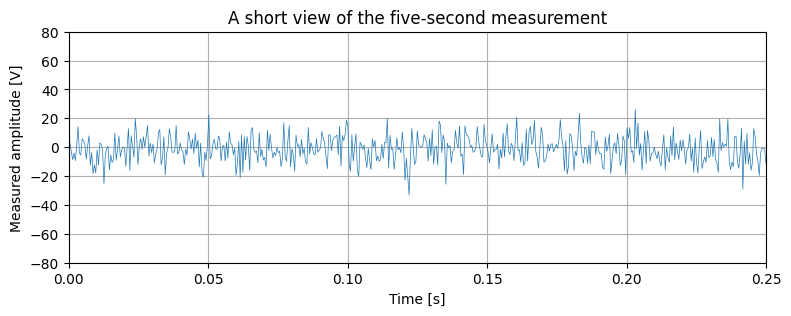

In [25]:
sampling_rate = 2048
duration = 5
time = np.arange(duration*sampling_rate)/sampling_rate
clean_signal = np.sin(2*np.pi*40*time)
rng = np.random.default_rng(7)
noise_draw = rng.normal(size=len(time))
noise_strength = 10  # Standard deviation in volts.
measured_signal = clean_signal + noise_strength*noise_draw

plt.plot(time, measured_signal, linewidth=.5)
plt.xlim(0, .25); plt.ylim(-80, 80)
plt.xlabel('Time [s]'); plt.ylabel('Measured amplitude [V]')
plt.title('A short view of the five-second measurement'); plt.show()


The time plot shows only the first quarter-second. The next cell uses **all five seconds** of measured samples. PSD means power spectral density; for voltage measurements its units are V²/Hz. Both panels below contain the same PSD values.


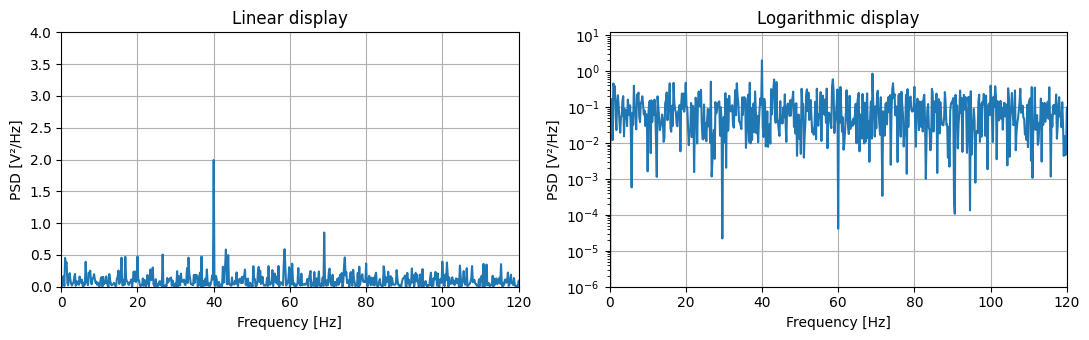

In [26]:
frequencies, density = sp.periodogram(measured_signal, fs=sampling_rate)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(frequencies, density)
axes[1].semilogy(frequencies, density)
axes[0].set(title='Linear display', ylim=(0, 4))
axes[1].set(title='Logarithmic display', ylim=(1e-6, 12))
for axis in axes:
    axis.set(xlim=(0, 120), xlabel='Frequency [Hz]', ylabel='PSD [V²/Hz]')
plt.tight_layout(); plt.show()


The clean signal is known because we simulated it; the periodogram receives only the noisy measurements. `semilogy` changes the display, retaining V²/Hz units. It does not convert the numbers to decibels.

**Noise strength and SNR:** `noise_strength` sets the standard deviation of the added samples. Doubling it quadruples the expected noise power. SNR compares signal power with noise power: −10 dB means ten times more noise power than signal power; −20 dB means one hundred times more. A logarithmic display changes neither ratio.

A seed makes an experiment repeatable. Rerunning the first cell resets the generator and repeats the same noise draw. Calling `rng.normal(...)` again without resetting it produces a fresh draw.


### Your turn

1. Compare noise strengths 0, 5, 10 and 20, using the **same** `noise_draw`. Plot the spectra with fixed axes. What stays fixed, and what changes?
2. At strength 10, make two fresh noise draws using `rng.normal(size=len(time))`. Compare their spectra. Which feature keeps returning, and which peaks move?
3. Explain what the logarithmic display makes easier to see. Does a visible tone imply that the total signal power exceeds the total noise power?


In [27]:
# Write your analysis here. Use the examples above as a starting point.


**What did you observe, and how do you explain it?**

*Write a few sentences here. Refer to a plotted feature or a measured value.*


## Investigation 2 — Why does averaging make the spectrum steadier?

A noise peak can be stronger than the tone in one short piece. Does it keep returning? Use a 32-second recording and keep every piece two seconds long. Here the pieces do not overlap, so the averaging is easy to follow. All spectra use the same Hann window; investigation 4 explains its effect.

**Lecture connection:** [slides 7;9](lecture-2.html#slide-7).


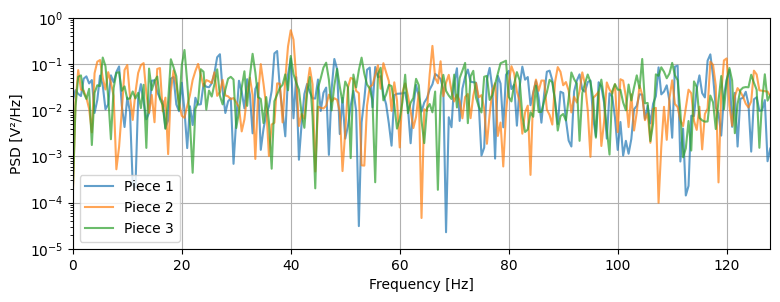

In [28]:
sampling_rate = 256
time = np.arange(32*sampling_rate)/sampling_rate
samples = (.6*np.sin(2*np.pi*40*time)
           + 2*np.random.default_rng(7).normal(size=len(time)))
segment_samples = 512  # Two seconds per spectrum; keep this fixed.
segment_densities = []
for start in range(0, len(samples), segment_samples):
    piece = samples[start:start+segment_samples]
    frequencies, density = sp.periodogram(piece, fs=sampling_rate, window='hann')
    segment_densities.append(density)
segment_densities = np.array(segment_densities)

for index in range(3):
    plt.semilogy(frequencies, segment_densities[index], alpha=.7,
                 label=f'Piece {index+1}')
plt.xlim(0, 128); plt.ylim(1e-5, 1)
plt.xlabel('Frequency [Hz]'); plt.ylabel('PSD [V²/Hz]')
plt.legend(); plt.show()


`segment_densities` has one row per piece and one column per frequency. Averaging down the rows (`axis=0`) combines the PSDs at each frequency. **Predict:** will averaging sixteen spectra divide the noise background by sixteen?


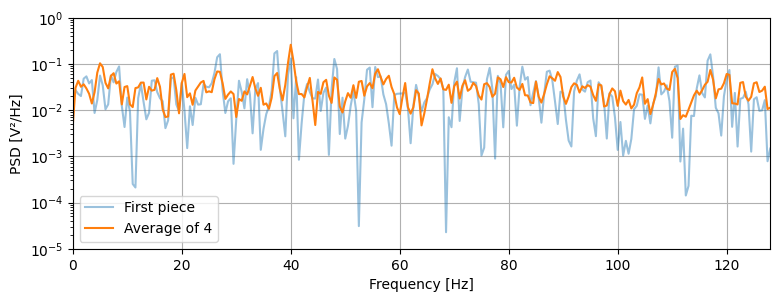

In [29]:
number_to_average = 4  # Try 1, 4 and 16; each piece stays two seconds long.
average_density = np.mean(segment_densities[:number_to_average], axis=0)
plt.semilogy(frequencies, segment_densities[0], alpha=.45, label='First piece')
plt.semilogy(frequencies, average_density, label=f'Average of {number_to_average}')
plt.xlim(0, 128); plt.ylim(1e-5, 1)
plt.xlabel('Frequency [Hz]'); plt.ylabel('PSD [V²/Hz]')
plt.legend(); plt.show()


### Your turn

Compare averages of 1, 4 and 16 pieces. Inspect the region from 60 to 110 Hz, away from the tone: does the typical background level fall, or does its scatter decrease?

Reproduce the sixteen-piece average using `sp.welch(samples, fs=sampling_rate, window='hann', nperseg=512, noverlap=0)`. Plot both results together.

Finally, compare Welch with a Hann periodogram of the **whole recording**. Explain why these two curves have different peak widths even though they use the same measurements. Has either operation changed the stored time samples?


In [30]:
# Write your analysis here. Use the examples above as a starting point.


**What did you observe, and how do you explain it?**

*Write a few sentences here. Refer to a plotted feature or a measured value.*


Averaging makes the noise background steadier; it does not remove that background. More pieces of the same length do not broaden the response. The whole-record periodogram uses 32 seconds per spectrum, whereas each piece in this Welch estimate uses two. Next we change that duration deliberately.


## Investigation 3 — A smoother spectrum—but have we lost a frequency?

Keep one 32-second recording fixed. It contains tones at 40 and 40.75 Hz. Now change how long each Welch piece lasts, keeping the window family and overlap fraction fixed.

**Lecture connection:** [slides 8](lecture-2.html#slide-8).


Piece duration: 2.0 s
Unpadded bin spacing: 0.5 Hz
Number of overlapping pieces: 31


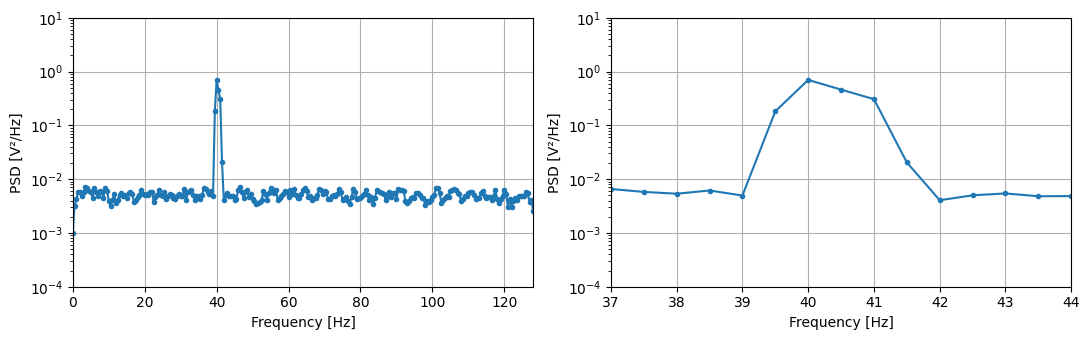

In [31]:
sampling_rate = 256
time = np.arange(32*sampling_rate)/sampling_rate
samples = (np.sin(2*np.pi*40*time) + .8*np.sin(2*np.pi*40.75*time)
           + .8*np.random.default_rng(11).normal(size=len(time)))
segment_samples = 512  # Then try 128 and 2048.
overlap_samples = segment_samples//2
frequencies, density = sp.welch(samples, fs=sampling_rate, window='hann',
    nperseg=segment_samples, noverlap=overlap_samples)
number_of_pieces = 1 + (len(samples)-segment_samples)//(segment_samples-overlap_samples)
print('Piece duration:', segment_samples/sampling_rate, 's')
print('Unpadded bin spacing:', sampling_rate/segment_samples, 'Hz')
print('Number of overlapping pieces:', number_of_pieces)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for axis in axes:
    axis.semilogy(frequencies, density, '.-')
    axis.set(ylim=(1e-4, 10), xlabel='Frequency [Hz]', ylabel='PSD [V²/Hz]')
axes[0].set_xlim(0, 128); axes[1].set_xlim(37, 44)
plt.tight_layout(); plt.show()


### Your turn

Compare 128, 512 and 2048 samples per piece. Before each run, calculate the duration and unpadded frequency-bin spacing. Record these alongside the number of pieces.

Which choice makes the background steadier? Which separates the two tones? Recommend a setting when separating the pair matters, and explain its cost.

If we recorded for longer while keeping `nperseg` fixed, which part of this compromise could improve? Does 50% overlap create independent new measurements?


In [32]:
# Write your analysis here. Use the examples above as a starting point.


**What did you observe, and how do you explain it?**

*Write a few sentences here. Refer to a plotted feature or a measured value.*


Without zero-padding, bin spacing is `sampling_rate/segment_samples = 1/piece_duration`. It is a useful scale, not a guarantee that any pair this far apart will be resolved: the window, relative strengths and noise also matter. Overlapping pieces share samples.


## Investigation 4 — Why does one tone produce many spectral bumps?

A physical oscillation can continue smoothly after our recording stops. The FFT only has the recorded piece. Imagine placing two copies side by side: do they join smoothly?

**Lecture connection:** [slides 10–12](lecture-2.html#slide-10).


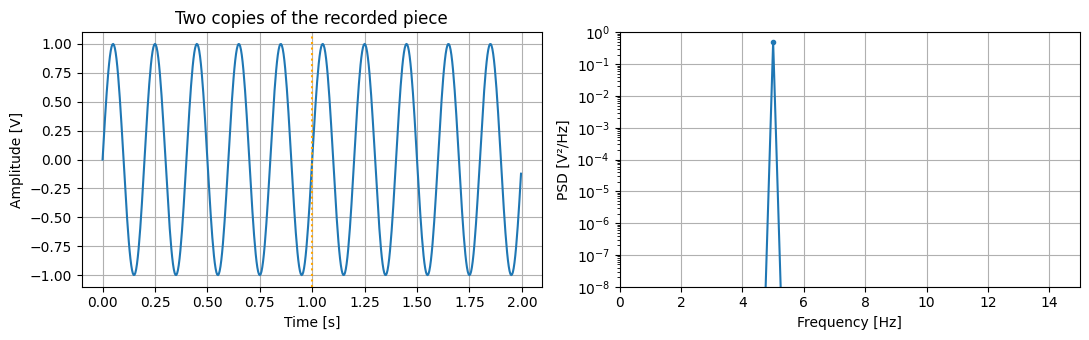

In [33]:
sampling_rate = 256
time = np.arange(256)/sampling_rate
frequency = 5  # Then try 5.25 Hz.
samples = np.sin(2*np.pi*frequency*time)
repeated_time = np.arange(2*len(samples))/sampling_rate
frequencies, density = sp.periodogram(samples, fs=sampling_rate, window='boxcar')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(repeated_time, np.tile(samples, 2))
axes[0].axvline(1, color='orange', linestyle=':')
axes[0].set(xlabel='Time [s]', ylabel='Amplitude [V]', title='Two copies of the recorded piece')
axes[1].semilogy(frequencies, density, '.-')
axes[1].set(xlim=(0, 15), ylim=(1e-8, 1), xlabel='Frequency [Hz]', ylabel='PSD [V²/Hz]')
plt.tight_layout(); plt.show()


Change only the frequency from 5 to 5.25 Hz. Describe the orange join and the extra spectral bumps. The join belongs to our repeated finite record; the physical source need not jump there.

A window multiplies the recorded samples by weights. Boxcar leaves them unchanged; a taper gives the ends less weight. The next example asks whether leakage from a strong tone can hide a weaker neighbour. `periodogram` applies the chosen weights for us. Here `nfft=2048` draws a denser frequency curve; keep it fixed until investigation 5.


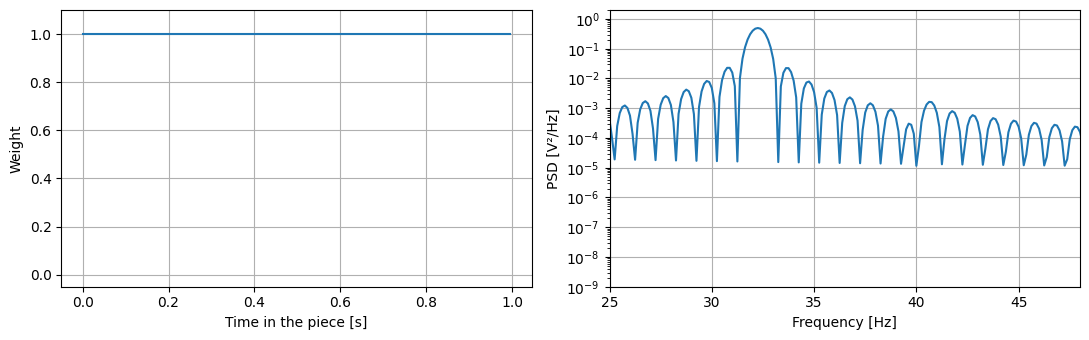

In [34]:
time = np.arange(256)/sampling_rate
samples = np.sin(2*np.pi*32.25*time) + .03*np.sin(2*np.pi*40.25*time)
window_name = 'boxcar'  # Try 'hann', 'hamming' and 'blackman'.
weights = sp.get_window(window_name, len(samples))
frequencies, density = sp.periodogram(samples, fs=sampling_rate,
    window=window_name, nfft=2048)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(time, weights)
axes[0].set(xlabel='Time in the piece [s]', ylabel='Weight', ylim=(-.05, 1.1))
axes[1].semilogy(frequencies, density)
axes[1].set(xlim=(25, 48), ylim=(1e-9, 2), xlabel='Frequency [Hz]', ylabel='PSD [V²/Hz]')
plt.tight_layout(); plt.show()


### Your turn

1. Compare boxcar, Hann, Hamming and Blackman on the same strong-tone/weak-neighbour recording. Keep the plot limits fixed. Which reveals the weak 40.25 Hz component most clearly? Inspect both the window weights and the spectrum.
2. Repeat using two similarly strong tones: `np.sin(2*np.pi*32.25*time) + .8*np.sin(2*np.pi*33.75*time)`. Which windows let you distinguish them?
3. Recommend a window for each task and explain why the answers can differ. If the close pair remains merged, what acquisition change would help?


In [35]:
# Write your analysis here. Use the examples above as a starting point.


**What did you observe, and how do you explain it?**

*Write a few sentences here. Refer to a plotted feature or a measured value.*


A taper can suppress distant leakage while broadening the central response. It can help reveal a weak neighbour yet merge a close pair. No window is best for every measurement. The whole-cycle boxcar example also shows why a steady tone does not always need tapering.


## Investigation 5 — Do more FFT points reveal more information?

Two tones at 32 and 32.75 Hz need time to drift apart. Compare adding zeros after a one-second recording with actually observing for longer.

**Lecture connection:** [slides 13](lecture-2.html#slide-13).


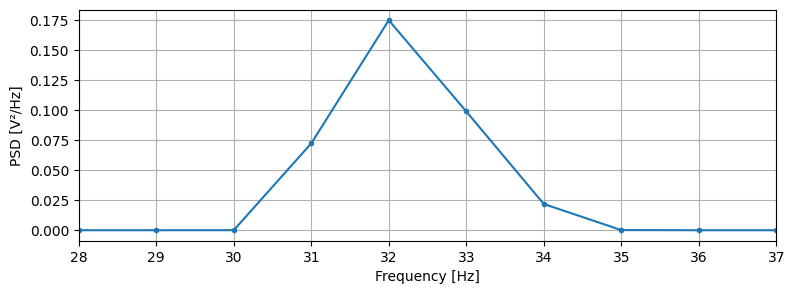

Measured duration: 1 s
Unpadded bin spacing: 1.0 Hz
Plotted frequency spacing: 1.0 Hz


In [36]:
sampling_rate = 256
duration = 1
padding_factor = 1
time = np.arange(duration*sampling_rate)/sampling_rate
samples = np.sin(2*np.pi*32*time) + .8*np.sin(2*np.pi*32.75*time)
frequencies, density = sp.periodogram(samples, fs=sampling_rate, window='hann',
    nfft=padding_factor*len(samples))
plt.plot(frequencies, density, '.-')
plt.xlim(28, 37); plt.xlabel('Frequency [Hz]'); plt.ylabel('PSD [V²/Hz]'); plt.show()
print('Measured duration:', duration, 's')
print('Unpadded bin spacing:', 1/duration, 'Hz')
print('Plotted frequency spacing:', frequencies[1]-frequencies[0], 'Hz')


### Your turn

Make three panels: (a) 1 s, no padding; (b) the same 1 s, padding factor 8; (c) 8 s of measured signal, no padding. Keep the signal frequencies, sampling rate and window fixed.

Report the number of measured samples and the plotted frequency spacing for each panel. Cases (b) and (c) have the same number of FFT points: do they distinguish the two tones equally well?

Explain which change adds information about the physical signal. Use `1/duration` as a starting scale, and remember the window also affects the response width.


In [37]:
# Write your analysis here. Use the examples above as a starting point.


**What did you observe, and how do you explain it?**

*Write a few sentences here. Refer to a plotted feature or a measured value.*


## Investigation 6 — Does equal noise strength mean equal difficulty?

Generate four kinds of noise with the same overall strength. Their fluctuations occur on different time scales. Compare both the waveforms and the spectra.

**Lecture connection:** [slides 15–16](lecture-2.html#slide-15).


Run this short helper to generate the noise. It starts with random samples, adjusts their frequency content for the chosen colour, then gives each result an RMS amplitude of 1 V. You can use the function as supplied; focus on what changes in the plots.


In [38]:
def make_noise(color, sampling_rate, duration, seed=7):
    rng = np.random.default_rng(seed)
    noise = rng.normal(size=int(duration*sampling_rate))
    frequencies = np.fft.rfftfreq(len(noise), d=1/sampling_rate)
    spectrum = np.fft.rfft(noise)
    slope = {'white': 0, 'pink': -1, 'brown': -2, 'blue': 1}[color]
    spectrum *= np.maximum(frequencies, 4)**(slope/2)
    spectrum[0] = 0  # Remove the average offset.
    noise = np.fft.irfft(spectrum, n=len(noise))
    return noise / np.std(noise)


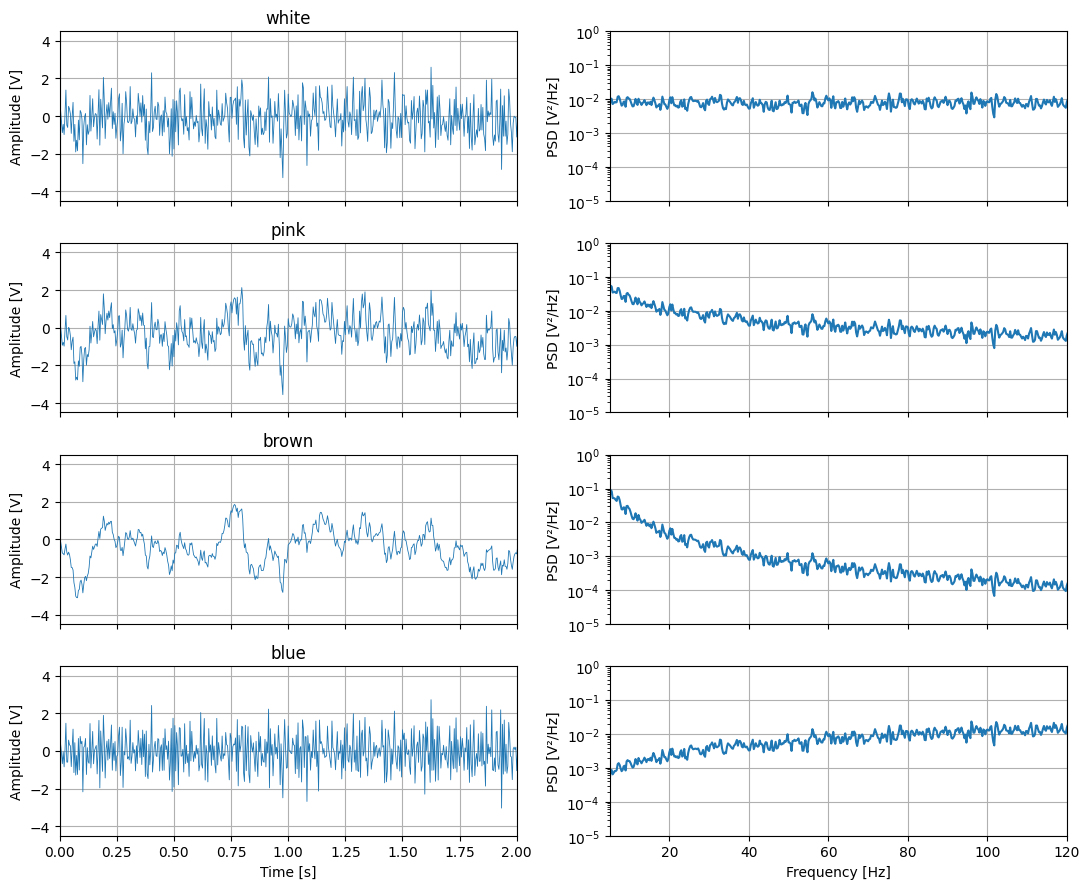

In [39]:
sampling_rate = 256
noise_records = {color: make_noise(color, sampling_rate, duration=30)
                 for color in ['white', 'pink', 'brown', 'blue']}
fig, axes = plt.subplots(4, 2, figsize=(11, 9), sharex='col', sharey='col')
for row, color in enumerate(['white', 'pink', 'brown', 'blue']):
    noise = noise_records[color]
    time = np.arange(len(noise))/sampling_rate
    frequencies, density = sp.welch(noise, fs=sampling_rate, window='hann', nperseg=1024)
    axes[row, 0].plot(time, noise, linewidth=.6)
    axes[row, 0].set(xlim=(0, 2), ylim=(-4.5, 4.5), ylabel='Amplitude [V]', title=color)
    axes[row, 1].semilogy(frequencies, density)
    axes[row, 1].set(xlim=(5, 120), ylim=(1e-5, 1), ylabel='PSD [V²/Hz]')
axes[-1, 0].set_xlabel('Time [s]'); axes[-1, 1].set_xlabel('Frequency [Hz]')
plt.tight_layout(); plt.show()


White noise has a flat **expected** density; a finite estimate still fluctuates. Pink and brown noise favour slower variations, while blue noise favours faster ones. In the helper, the colour weighting flattens below 4 Hz to keep the slowest variations bounded. RMS is simply the common overall strength used for this comparison. The seed keeps the comparison repeatable.


### Your turn

Predict whether a weak 15 Hz tone or a weak 90 Hz tone will be easier to see in brown noise. Add each tone **separately**, with amplitude 0.2 V, and compare with the original noise-only PSD.

Repeat with white noise. Keep amplitude, segment duration, window and axes fixed. Explain why moving the tone helps more in one background.

Does “white” describe the distribution of sample values, or their frequency content? Could white noise have Gaussian sample values?


In [40]:
# Write your analysis here. Use the examples above as a starting point.


**What did you observe, and how do you explain it?**

*Write a few sentences here. Refer to a plotted feature or a measured value.*


## Investigation 7 — Find the same chirp in two backgrounds

Put the earlier comparisons together with a signal whose pitch changes. The same chirp is added to white and brown noise. A chirp is one oscillation whose frequency changes with time. Predict which background will hide more of it.

**Lecture connection:** [slides 17–19](lecture-2.html#slide-17).


In [41]:
sampling_rate = 2048
time = np.arange(30*sampling_rate)/sampling_rate
event_start = 7.5
event_duration = 15
start_frequency = 200
end_frequency = 600
event = (time >= event_start) & (time < event_start + event_duration)
time_in_event = time[event] - event_start
chirp_signal = np.zeros_like(time)
chirp_signal[event] = .5*sp.chirp(time_in_event, f0=start_frequency, f1=end_frequency,
    t1=event_duration, method='logarithmic')


A 200–600 Hz oscillation is too fast to inspect over thirty seconds on one axis. The top panel shows the **known frequency we put into the simulation**, during the active interval. Below it, three views each show just **20 milliseconds** of the clean waveform.

The dots are the actual samples. The smooth lines show the simulated continuous wave for comparison. Count the cycles in each view: what changes between the early and late parts of the chirp?


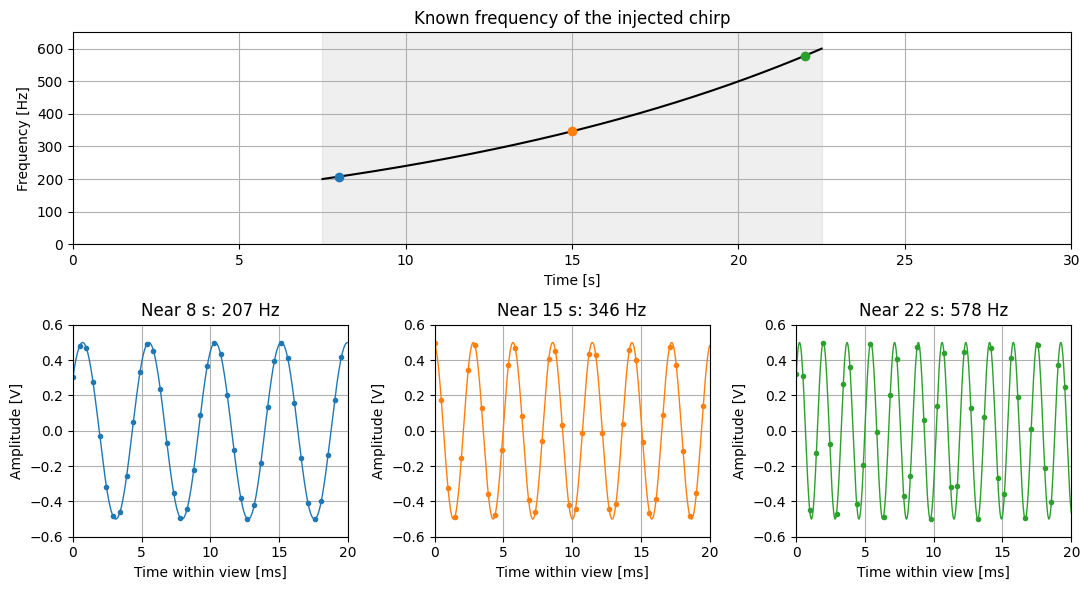

In [42]:
injected_frequency = start_frequency*(end_frequency/start_frequency)**(time_in_event/event_duration)
fig = plt.figure(figsize=(11, 6))
grid = fig.add_gridspec(2, 3)
frequency_axis = fig.add_subplot(grid[0, :])
frequency_axis.axvspan(event_start, event_start+event_duration, color='grey', alpha=.12)
frequency_axis.plot(time[event], injected_frequency, color='black')
frequency_axis.set(xlim=(0, 30), ylim=(0, 650), xlabel='Time [s]',
                   ylabel='Frequency [Hz]', title='Known frequency of the injected chirp')

for column, (start, color) in enumerate(zip([8, 15, 22], ['tab:blue', 'tab:orange', 'tab:green'])):
    frequency_here = start_frequency*(end_frequency/start_frequency)**((start-event_start)/event_duration)
    frequency_axis.plot(start, frequency_here, 'o', color=color)
    axis = fig.add_subplot(grid[1, column])
    selected = (time >= start) & (time < start+.020)
    smooth_time = np.linspace(start, start+.020, 1000)
    smooth_wave = .5*sp.chirp(smooth_time-event_start, f0=start_frequency, f1=end_frequency,
                            t1=event_duration, method='logarithmic')
    axis.plot(1000*(smooth_time-start), smooth_wave, color=color, linewidth=1)
    axis.plot(1000*(time[selected]-start), chirp_signal[selected], '.', color=color)
    axis.set(xlim=(0, 20), ylim=(-.6, .6), xlabel='Time within view [ms]',
             ylabel='Amplitude [V]', title=f'Near {start} s: {frequency_here:.0f} Hz')
plt.tight_layout(); plt.show()


The event has its own clock, starting at zero. Its specified frequency reaches 600 Hz after 15 seconds. The sampling rate is above twice that frequency. Now use `make_noise` from investigation 6 to generate two new backgrounds at this sampling rate, both with RMS amplitude 1 V. For each before/after comparison, keep the **same noise samples** and add the chirp to them.


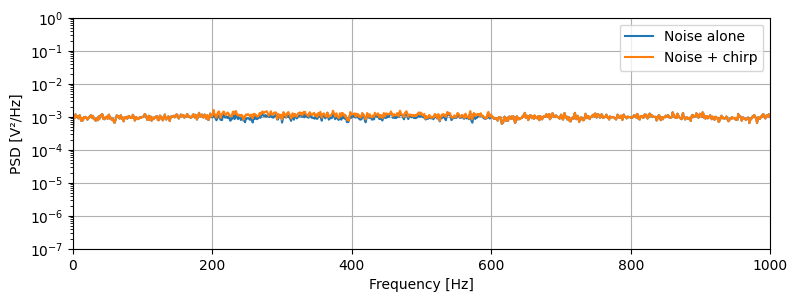

In [45]:
backgrounds = {color: make_noise(color, sampling_rate, duration=30, seed=17)
               for color in ['white', 'brown']}
noise_kind = 'white'  # Then try 'brown'.
noise = backgrounds[noise_kind]
combined_signal = noise + chirp_signal
frequencies, noise_density = sp.welch(noise, fs=sampling_rate, window='hann', nperseg=2048)
frequencies, combined_density = sp.welch(combined_signal, fs=sampling_rate, window='hann', nperseg=2048)
plt.semilogy(frequencies, noise_density, label='Noise alone')
plt.semilogy(frequencies, combined_density, label='Noise + chirp')
plt.xlim(0, 1000); plt.ylim(1e-7, 1)
plt.xlabel('Frequency [Hz]'); plt.ylabel('PSD [V²/Hz]')
plt.legend(); plt.show()


### Your turn

1. Produce the comparison for **both** backgrounds with the same axes and Welch settings. Where is the chirp most visible? Explain using the noise level in the 200–600 Hz band.
2. For each background, calculate `combined_density - noise_density`. Plot this difference on a **linear** vertical axis and compare it with the chirp-only PSD. Does subtraction isolate the chirp exactly? Why can the difference be negative, and why should we avoid taking its logarithm?
3. Use the brown-noise recording plus chirp. Compare three **3-second intervals beginning at 1, 13.5 and 26 s**, retaining the one-second Welch pieces (`nperseg=2048`). Label each curve with its time interval. Which contains the event? What can these local spectra tell you that the whole-record PSD cannot?
4. Distinguish the 3-second interval being examined from the 1-second pieces Welch averages inside it. Can three selected intervals locate the event boundaries precisely?


<details><summary>A small hint, if needed</summary>

Select a time interval with sample indices: `samples[int(start*sampling_rate):int(end*sampling_rate)]`. Use equal interval lengths and the same Welch settings for a fair comparison. Noise and chirp can reinforce or oppose one another in a finite recording, so subtracting estimated PSDs need not give the chirp-only PSD.

</details>


In [ ]:
# Write your analysis here. Use the examples above as a starting point.


**What did you observe, and how do you explain it?**

*Write a few sentences here. Refer to a plotted feature or a measured value.*


A whole-record PSD keeps no time axis. Labelling local spectra preserves the intervals they describe. In Lecture 3 we will arrange many such spectra into an image: a spectrogram.


## Investigation 8 — Repair an analysis and defend your choices

A calibration source has tones at 40, 40.75 and 90 Hz; the last is much weaker. The acquisition below is correct. Keep its samples and sampling rate fixed. An analyst claims that a large FFT guarantees the two close tones will be resolved. Use the evidence to assess and repair the analysis.

**Lecture connection:** [slides 20;7–9;13](lecture-2.html#slide-20).


In [47]:
sampling_rate = 256
time = np.arange(32*sampling_rate)/sampling_rate
calibration_record = (np.sin(2*np.pi*40*time)
                      + .8*np.sin(2*np.pi*40.75*time)
                      + .15*np.sin(2*np.pi*90*time)
                      + .8*np.random.default_rng(21).normal(size=len(time)))


The following analysis runs, but its parameter choices, interpretation and units need review. Run it and inspect what is visible. The large `nfft` is intentional: do not assume more plotted points mean more measured information.


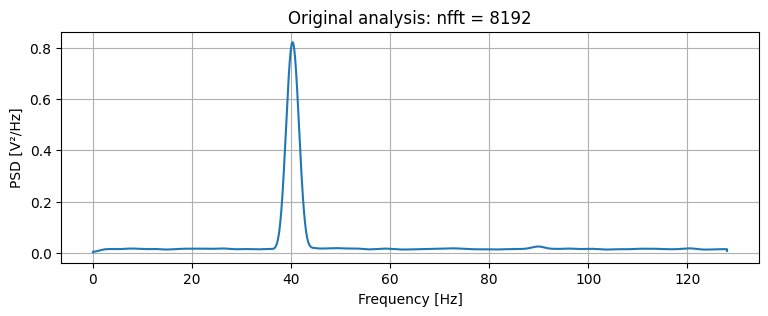

In [49]:
frequencies, spectrum = sp.welch(calibration_record, fs=sampling_rate,
    window='hann', nperseg=128, nfft=8192, scaling='spectrum')
plt.plot(frequencies, spectrum)
plt.xlabel('Frequency [Hz]'); plt.ylabel('PSD [V²/Hz]')
plt.title('Original analysis: nfft = 8192'); plt.show()


### Your turn

Produce a physically meaningful PSD that lets you assess all three known tones. Keep the acquisition fixed.

- Compare at least two segment lengths on the **same data**, using the same window and overlap fraction. Calculate their durations and unpadded bin spacings.
- Use an appropriate display scale and a close-up of the 40/40.75 Hz pair. Check the weaker component near 90 Hz.
- Make the chosen scaling and vertical-axis units agree. Explain the difference between `scaling='spectrum'` and `scaling='density'` at the level of their units.
- Explain what the original `nfft=8192` did, and why it could not compensate for the short measured pieces.

For each repair, state **the original problem → your change → visible or numerical evidence**. Report the recovered frequencies and justify your final compromise between frequency detail and background fluctuations. A log scale or a different segment length is a choice to justify, not a universal rule.


<details><summary>A small hint, if needed</summary>

The recording lasts 32 seconds, but the original Welch pieces last only 128/256 = 0.5 seconds. Look back at investigations 3 and 5. `scaling="density"` supplies V²/Hz for these voltage measurements; `scaling="spectrum"` supplies V².

</details>


In [ ]:
# Write your analysis here. Use the examples above as a starting point.


**What did you observe, and how do you explain it?**

*Write a few sentences here. Refer to a plotted feature or a measured value.*


## Optional investigation 9 — What if the measurements are unevenly spaced?

An observer measures a star at irregular times over 30 days. Use the actual observation times to search for a repeating rhythm. This optional exercise uses Lomb–Scargle; it does not require you to implement the fitting algorithm.

**Lecture connection:** [slides 14](lecture-2.html#slide-14).


The supplied simulation has a period of `1/0.37` days. Our task is to recover it from the noisy observations. The trial frequencies below are in **cycles per day**, because the times are in days. SciPy expects angular frequencies, so we pass `2*np.pi*trial_frequencies`.

`floating_mean=True` fits a constant level along with the sinusoid. `normalize=True` gives a dimensionless score; this plot is **not a PSD in V²/Hz**. This example requires SciPy 1.15 or later, included in the notebook requirements. [Function documentation](https://docs.scipy.org/doc/scipy-1.15.0/reference/generated/scipy.signal.lombscargle.html).


Best frequency: 0.3699 cycles/day
Recovered period: 2.703 days


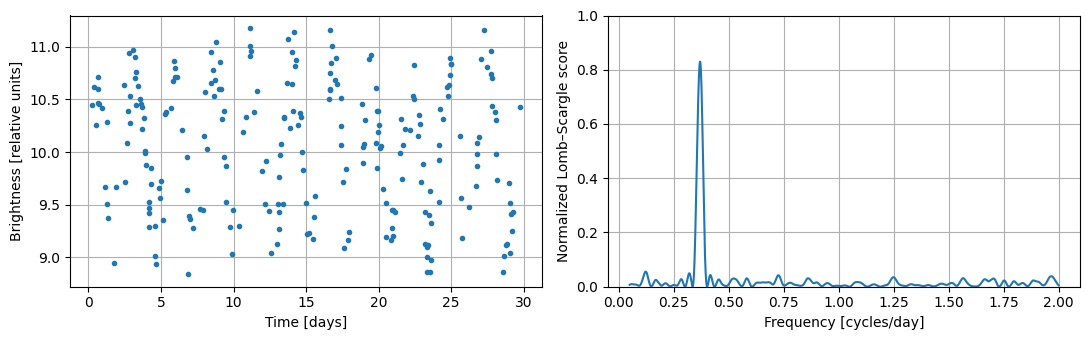

In [53]:
rng = np.random.default_rng(42)
observation_times = np.sort(rng.uniform(0, 30, 240))
brightness = (10 + .8*np.sin(2*np.pi*.37*observation_times + .4)
              + .25*rng.normal(size=len(observation_times)))
trial_frequencies = np.linspace(.05, 2, 2500)
score = sp.lombscargle(observation_times, brightness, 2*np.pi*trial_frequencies,
    normalize=True, floating_mean=True)
best_frequency = trial_frequencies[np.argmax(score)]
print('Best frequency:', round(best_frequency, 4), 'cycles/day')
print('Recovered period:', round(1/best_frequency, 3), 'days')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(observation_times, brightness, '.')
axes[0].set(xlabel='Time [days]', ylabel='Brightness [relative units]')
axes[1].plot(trial_frequencies, score)
axes[1].set(xlabel='Frequency [cycles/day]', ylabel='Normalized Lomb–Scargle score', ylim=(0, 1))
plt.tight_layout(); plt.show()


The helper below adjusts a cosine, a sine and a constant at one chosen frequency. Their combination is a sinusoid with a fitted amplitude, phase and average level. You can use the function as supplied; the linear-algebra details are outside this investigation.


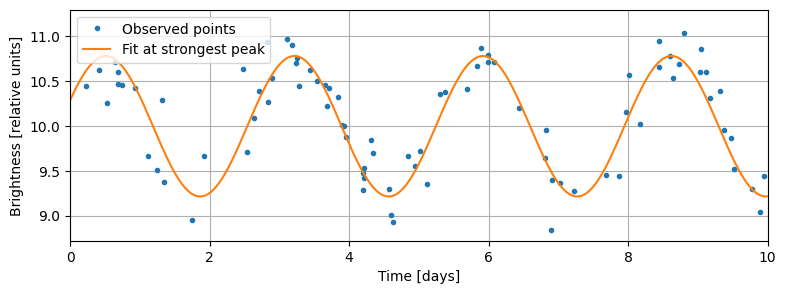

In [56]:
def fit_sinusoid(times, values, frequency, plot_times):
    basis = np.column_stack([np.cos(2*np.pi*frequency*times),
                             np.sin(2*np.pi*frequency*times), np.ones_like(times)])
    coefficients = np.linalg.lstsq(basis, values, rcond=None)[0]
    plot_basis = np.column_stack([np.cos(2*np.pi*frequency*plot_times),
                                  np.sin(2*np.pi*frequency*plot_times), np.ones_like(plot_times)])
    return plot_basis @ coefficients

plot_times = np.linspace(0, 30, 1500)
fitted_curve = fit_sinusoid(observation_times, brightness, best_frequency, plot_times)
plt.plot(observation_times, brightness, '.', label='Observed points')
plt.plot(plot_times, fitted_curve, label='Fit at strongest peak')
plt.xlim(0, 10); plt.xlabel('Time [days]'); plt.ylabel('Brightness [relative units]')
plt.legend(); plt.show()


### Your turn

Suppose the observer can observe during only the first quarter of each day. Select the existing points with `keep = observation_times % 1 < 0.25`, then recompute Lomb–Scargle using those times and brightness values. Do not generate new brightness values.

Overlay the scores before and after introducing the daily gaps. Compare the strongest peak and the competing peaks. Plot the fitted sinusoid at the strongest peak against the remaining observations.

Why would assigning these points evenly spaced times change the problem? Does Lomb–Scargle fill the gaps or guarantee a unique period? Explain what the competing peaks mean without treating the score as a probability.


In [ ]:
# Write your analysis here. Use the examples above as a starting point.


**What did you observe, and how do you explain it?**

*Write a few sentences here. Refer to a plotted feature or a measured value.*


## Before you finish

Can you explain what each plot tells you, why you chose the sampling rate and analysis settings, and what the analysis cannot recover? Label axes with quantities and units. Restart the kernel and run all cells to check that your work is reproducible.
